# Imports & Setup

In [1]:
import torch
import torch.nn as nn
import numpy as np
import time
import sys
import os
import pandas as pd
from datetime import datetime

project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.append(project_root)

from utils.dataset_loader import load_data
from utils.visualize import (plot_loss_and_acc_curve,get_all_preds_and_true,plot_confusion_matrix,plot_classification_report)
from utils.tools import (freeUpMemories, get_optimizer, load_loading_config, load_training_config)

# Config

In [ ]:
load_config_id = 8
training_config_id = 3

# Loading Config
config = load_loading_config(load_config_id)
load_method = config['load_method']
window_size = config['window_size']
stride = config['stride']
use_pca = config['use_pca']
use_psd = config['use_psd']
psd_bands = config['psd_bands']
use_psd_pca = config['use_psd_pca']
use_de = config['use_de']
de_bands = config['de_bands']
use_de_pca = config['use_de_pca']
apply_filter = config['apply_filter']
lowcut: float = config['lowcut']
highcut: float = config['highcut']
fs_value: int = config['fs_value']
filter_order = config['filter_order']
apply_baseline = config['apply_baseline']
baseline_window = config['baseline_window']
normalize = config['normalize']
normalization_method = config['normalization_method']

# Training Config
training_config = load_training_config(training_config_id)
random_seed = training_config['random_seed']
np.random.seed(random_seed)
torch.manual_seed(random_seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device :",device)
if device.type == "cuda": torch.cuda.set_per_process_memory_fraction(0.9)
apply_train_test_split = training_config['apply_train_test_split']
test_size = training_config['test_size']
epochs = training_config['epochs']
batch_size = training_config['batch_size']
num_classes = training_config['num_classes']
sigmoid_threshold = training_config['sigmoid_threshold']

# Optimizer Config
optimizer_type = training_config['optimizer_type']
learning_rate = training_config['learning_rate']
learning_rate_to_save = training_config['learning_rate_to_save']
weight_decay = training_config['weight_decay']
momentum = training_config['momentum']
betas = training_config['betas']

# Model config
model_name = "1D_CNN_Residual_Blocks"
kernel_size: int = 7
dropout=0.3

device : cuda


# Load & Preprocess & Split Data

In [3]:
train_loader, test_loader, ratio, input_size = load_data(load_method,window_size,stride,apply_filter, lowcut,
	highcut, fs_value, filter_order,apply_baseline,baseline_window, normalize, normalization_method,
	apply_train_test_split,test_size,random_seed,batch_size,True,None,None,num_classes,use_psd,psd_bands,
	use_psd_pca,use_de,de_bands,use_de_pca,use_pca,None)


full_path : C:\FACED dataset\Preprocessed_data\pre_XY_win500_str500_low1_high50_fs250_order4_base20_norm_zscore_psd[2, 3]pca_de[1, 2, 3, 4]pca_pca.pkl
file exists , loading ...
Existing Data Shape: (51660, 500, 112) (51660,)
start to binarize labels
y_all classes :  [0 1] Class counts: [27900 23760]
start to train_test_split
start to dataloader creation
returned train_loader, test_loader


# 1D_CNN_Residual_Blocks Model

In [4]:
try:
    freeUpMemories(model)
except Exception as e:
    freeUpMemories()
    print("error when deleting model :",e)

error when deleting model : name 'model' is not defined


In [ ]:
# if num_classes == 2:  
#     pos_weight_val = torch.tensor([ratio]).to(device)
#     criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)
# elif num_classes == 8:  
#     criterion = nn.CrossEntropyLoss()

# class ResidualBlock1D(nn.Module):
#     def __init__(self, in_channels, out_channels, kernel_size=kernel_size, stride=1):
#         super(ResidualBlock1D, self).__init__()
#         padding = kernel_size // 2
#         self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, stride=stride)
#         self.bn1 = nn.BatchNorm1d(out_channels)
#         self.relu = nn.ReLU()
#         self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding)
#         self.bn2 = nn.BatchNorm1d(out_channels)

#         self.downsample = nn.Identity()
#         if in_channels != out_channels or stride != 1:
#             self.downsample = nn.Sequential(
#                 nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride),
#                 nn.BatchNorm1d(out_channels)
#             )

#     def forward(self, x):
#         identity = self.downsample(x)
#         out = self.relu(self.bn1(self.conv1(x)))
#         out = self.bn2(self.conv2(out))
#         out += identity
#         return self.relu(out)

# class Residual1DCNN(nn.Module):
#     def __init__(self, num_classes=num_classes, input_size=input_size,kernel_size=kernel_size):
#         super(Residual1DCNN, self).__init__()
#         padding = kernel_size // 2
#         self.initial = nn.Sequential(
#             nn.Conv1d(input_size, 64, kernel_size=kernel_size, padding=padding),
#             nn.BatchNorm1d(64),
#             nn.ReLU()
#         )
#         self.block1 = ResidualBlock1D(64, 64, kernel_size=kernel_size, stride=1)
#         self.block2 = ResidualBlock1D(64, 128, kernel_size=kernel_size, stride=2)
#         self.block3 = ResidualBlock1D(128, 256, kernel_size=kernel_size, stride=2)

#         self.pool = nn.AdaptiveAvgPool1d(1)
#         out_features = 1 if num_classes == 2 else num_classes
#         self.fc = nn.Linear(256, out_features)

#     def forward(self, x):
#         x = x.permute(0, 2, 1)  # (B, T, C) → (B, C, T)
#         x = self.initial(x)
#         x = self.block1(x)
#         x = self.block2(x)
#         x = self.block3(x)
#         x = self.pool(x).squeeze(-1)
#         return self.fc(x)

# model = Residual1DCNN(num_classes,input_size,kernel_size).to(device)
# optimizer = get_optimizer(model,optimizer_type,learning_rate,weight_decay,momentum,betas)

In [ ]:
if num_classes == 2:  
    pos_weight_val = torch.tensor([ratio]).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)
elif num_classes == 8:  
    criterion = nn.CrossEntropyLoss()

class ResidualBlock1D(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=7, stride=1, dropout=0.2):
        super(ResidualBlock1D, self).__init__()
        padding = kernel_size // 2
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size, stride=stride, padding=padding)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.act = nn.SiLU()
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding)
        self.bn2 = nn.BatchNorm1d(out_channels)

        self.downsample = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride),
                nn.BatchNorm1d(out_channels)
            )

    def forward(self, x):
        identity = self.downsample(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.act(out)
        out = self.dropout(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += identity
        return self.act(out)


class Residual1DCNN(nn.Module):
    def __init__(self, num_classes=num_classes, input_size=input_size,kernel_size=kernel_size,dropout=dropout):
        super(Residual1DCNN, self).__init__()
        padding = kernel_size // 2

        self.initial = nn.Sequential(
            nn.Conv1d(input_size, 64, kernel_size=kernel_size, padding=padding),
            nn.BatchNorm1d(64),
            nn.SiLU()
        )

        self.res_blocks = nn.Sequential(
            ResidualBlock1D(64, 64, kernel_size, stride=1, dropout=dropout),
            ResidualBlock1D(64, 128, kernel_size, stride=2, dropout=dropout),
            ResidualBlock1D(128, 256, kernel_size, stride=2, dropout=dropout),
            ResidualBlock1D(256, 256, kernel_size, stride=1, dropout=dropout) 
        )

        self.pool = nn.AdaptiveAvgPool1d(1)
        out_features = 1 if num_classes == 2 else num_classes

        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, out_features)
        )
    
    def forward(self, x):
        x = x.permute(0, 2, 1)  # (B, T, C) → (B, C, T)
        x = self.initial(x)
        x = self.res_blocks(x)
        x = self.pool(x).squeeze(-1)
        return self.fc(x)


model = Residual1DCNN(num_classes,input_size,kernel_size,dropout).to(device)
optimizer = get_optimizer(model,optimizer_type,learning_rate,weight_decay,momentum,betas)

In [7]:
# Test Model
x = torch.randn(16, window_size, input_size).to(device)
y = model(x)
if y.shape[0] != 16:
    raise Exception("Model mismatch")


# Training and Evaluation

In [8]:
def train(model, loader, optimizer, criterion, device, num_classes):
    model.train()
    total_loss = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        if num_classes == 2:
            y = y.float().unsqueeze(1)

        optimizer.zero_grad()
        out = model(X)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def evaluate(model, loader, device, num_classes,sigmoid_threshold=sigmoid_threshold):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            out = model(X)

            if num_classes == 2:
                preds = torch.sigmoid(out)
                preds = (preds > sigmoid_threshold).int().squeeze()
            else:
                preds = out.argmax(dim=1)
            correct += (preds == y).sum().item()
            total += y.size(0)
    return correct / total

# Run Training

In [9]:
train_accs, test_accs = [], []
train_losses, test_losses = [], []
epoch_times = []

early_stop_patience = 10
best_loss = float('inf')  
best_accuracy = 0.0
epochs_no_improve = 0
early_stop_triggered = False
best_model_state = None
last_epoch = 0

In [10]:
print("start traning at :",datetime.now().strftime( "%H:%M:%S"))

for epoch in range(1, epochs + 1):
    start_time = time.time()
    
    train_loss = train(model, train_loader, optimizer, criterion, device, num_classes)
    train_acc = evaluate(model, train_loader, device, num_classes,sigmoid_threshold)

    test_loss = 0
    model.eval()
    with torch.no_grad():
        total_loss = 0
        for X, y in test_loader:
            X, y = X.to(device), y.to(device)
            if num_classes == 2:
                y = y.float().unsqueeze(1)
            out = model(X)
            loss = criterion(out, y)
            total_loss += loss.item()
        test_loss = total_loss / len(test_loader)
    
    test_acc = evaluate(model, test_loader, device, num_classes,sigmoid_threshold)
    
    end_time = time.time()
    epoch_duration = end_time - start_time

    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    epoch_times.append(epoch_duration)
    last_epoch = epoch

    print(f"Epoch {epoch}/{epochs} - Time: {epoch_duration:.2f}s - "
        f"Train Loss: {train_loss:.4f} - Test Loss: {test_loss:.4f} - "
        f"Train Acc: {train_acc:.4f} - Test Acc: {test_acc:.4f}")
    
    
	# Early stopping logic
    if test_loss < best_loss - 1e-4:
        best_loss = test_loss
        best_accuracy = test_acc
        epochs_no_improve = 0
        best_model_state = model.state_dict()
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= early_stop_patience:
            print(f"Early stopping triggered at epoch {epoch} ⛔")
            early_stop_triggered = True
            break


start traning at : 10:32:10
Epoch 1/100 - Time: 49.49s - Train Loss: 0.7488 - Test Loss: 0.7406 - Train Acc: 0.5738 - Test Acc: 0.5498
Epoch 2/100 - Time: 33.94s - Train Loss: 0.7283 - Test Loss: 0.7303 - Train Acc: 0.6047 - Test Acc: 0.5628
Epoch 3/100 - Time: 34.43s - Train Loss: 0.7126 - Test Loss: 0.7207 - Train Acc: 0.6396 - Test Acc: 0.6000
Epoch 4/100 - Time: 34.65s - Train Loss: 0.6934 - Test Loss: 0.7033 - Train Acc: 0.6641 - Test Acc: 0.6174
Epoch 5/100 - Time: 35.66s - Train Loss: 0.6734 - Test Loss: 0.7031 - Train Acc: 0.6700 - Test Acc: 0.6133
Epoch 6/100 - Time: 34.73s - Train Loss: 0.6522 - Test Loss: 0.6848 - Train Acc: 0.7117 - Test Acc: 0.6447
Epoch 7/100 - Time: 34.32s - Train Loss: 0.6329 - Test Loss: 0.6722 - Train Acc: 0.7301 - Test Acc: 0.6521
Epoch 8/100 - Time: 34.27s - Train Loss: 0.6140 - Test Loss: 0.6703 - Train Acc: 0.7424 - Test Acc: 0.6613
Epoch 9/100 - Time: 34.00s - Train Loss: 0.5939 - Test Loss: 0.6644 - Train Acc: 0.7619 - Test Acc: 0.6738
Epoch 10/

In [11]:
model_save_path = f"../results/models/{model_name}_loadId_{load_config_id}_trainId_{training_config_id}.pth"
torch.save({
    'model_state_dict': best_model_state,
    'optimizer_state_dict': optimizer.state_dict(),
    'epoch': last_epoch,
    'train_losses': train_losses,
    'test_losses': test_losses,
    'train_accs': train_accs,
    'test_accs': test_accs,
    'best_accuracy': best_accuracy,
    'num_classes': num_classes,
    'input_size': input_size,
    'kernel_size': kernel_size,
    'dropout': dropout
}, model_save_path)


# Plot Results

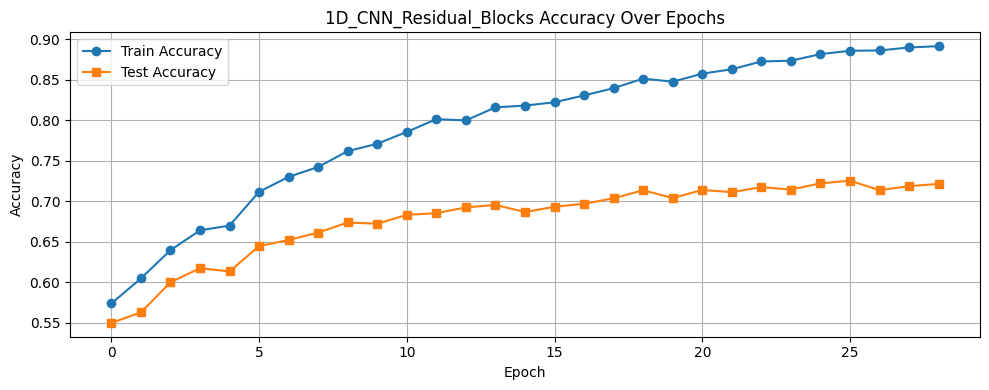

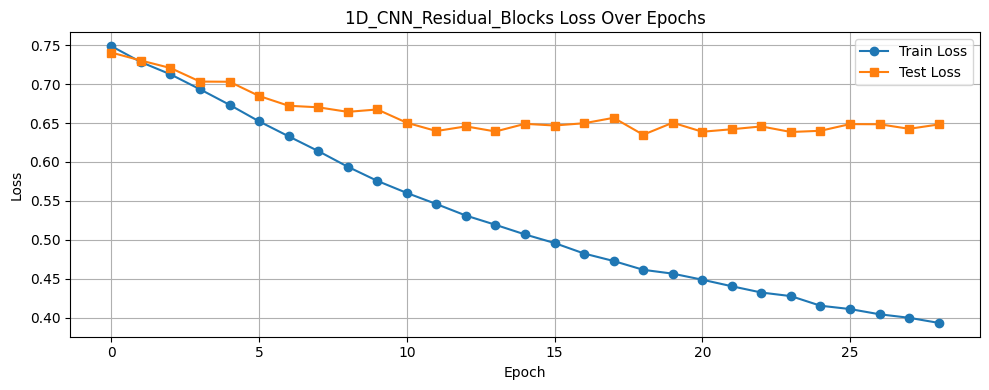

In [12]:
acc_path, loss_path = plot_loss_and_acc_curve(train_accs,test_accs,train_losses,test_losses,model_name)

In [13]:
all_preds, all_trues = get_all_preds_and_true(model,test_loader,device,num_classes,sigmoid_threshold=sigmoid_threshold)

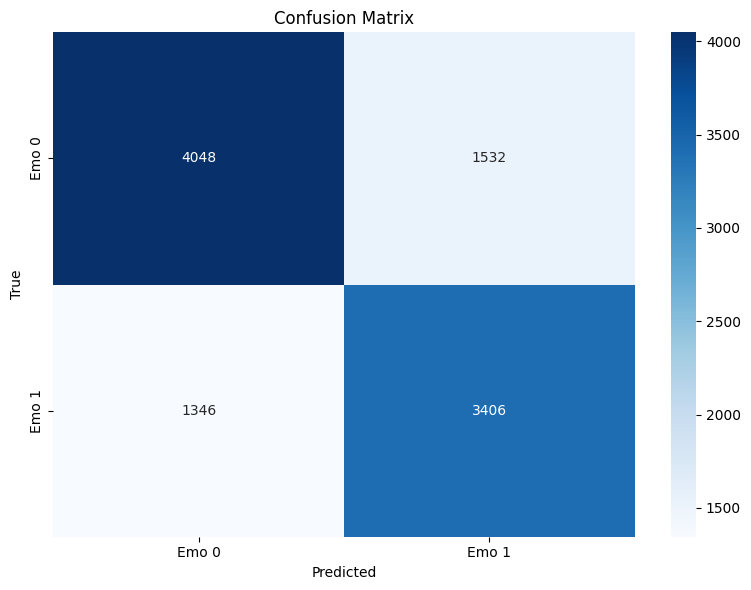

In [14]:
cm_path = plot_confusion_matrix(all_preds,all_trues,num_classes,model_name)

{'0.0': {'precision': 0.7504634779384501, 'recall': 0.7254480286738352, 'f1-score': 0.7377437579733916, 'support': 5580.0}, '1.0': {'precision': 0.6897529364115026, 'recall': 0.7167508417508418, 'f1-score': 0.7029927760577915, 'support': 4752.0}, 'accuracy': 0.721447928765002, 'macro avg': {'precision': 0.7201082071749764, 'recall': 0.7210994352123385, 'f1-score': 0.7203682670155915, 'support': 10332.0}, 'weighted avg': {'precision': 0.7225408595358122, 'recall': 0.7214479287650021, 'f1-score': 0.7217607279634293, 'support': 10332.0}}


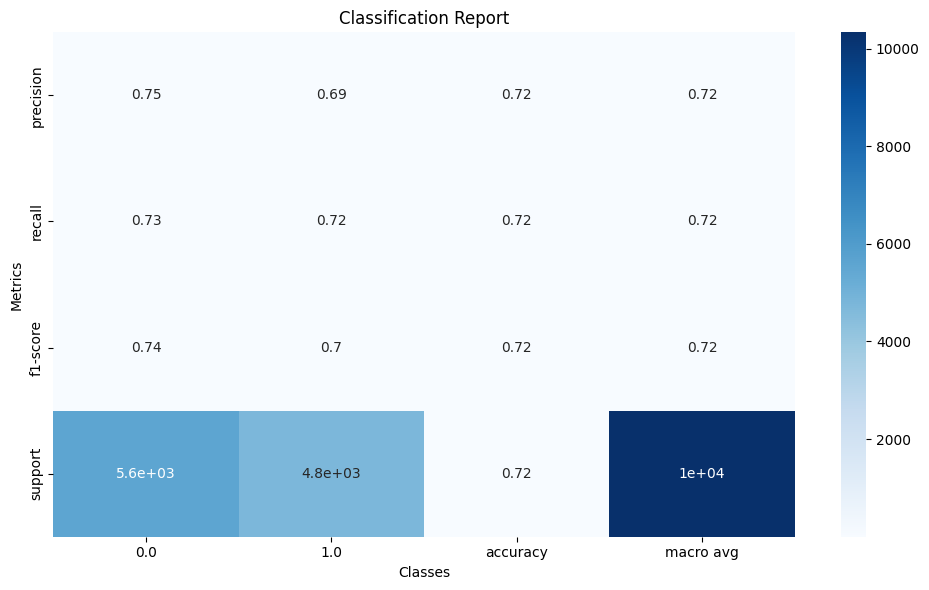

In [15]:
cr_path = plot_classification_report(all_preds,all_trues,model_name)

In [16]:
results_file = "../results/results_summary.xlsx"
sheet_name = model_name

final_train_acc = round(train_accs[-1], 6)
final_test_acc = round(test_accs[-1], 6)
final_train_loss = round(train_losses[-1], 6)
final_test_loss = round(test_losses[-1], 6)
avg_epoch_time = round(sum(epoch_times) / len(epoch_times), 3)

run_time = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

config_dict = {
    "Timestamp": run_time,
    
	# Load Config
    "Config_Id": str(load_config_id),
	"window_size": str(window_size),
    "strdie": str(stride),
    "use_psd": str(use_psd),
    "use_de": str(use_de),
    "psd_bands": str(psd_bands),
    "use_psd_pca": str(use_psd_pca),
    "de_bands": str(de_bands),
    "use_de_pca": str(use_de_pca),
    "use_pca": str(use_pca),
    
	# Model Config
	"Model": str(model_name),
	"kernel_size": str(kernel_size),
    "dropout": str(dropout),

	# Training Config
    "Trainging_Config_Id": str(training_config_id),
    "Epochs": str(epochs),
    "Batch Size": str(batch_size),
    "Optimizer": str(optimizer_type),
    "LR": str(learning_rate_to_save) + " lr",
    "Weight Decay": str(weight_decay),
    "Momentum": str(momentum),
    "Betas": str(betas),
	"Num Classes": str(num_classes),
    "Input Size": str(input_size),
	"Device": str(device),
    "sigmoid_threshold": str(sigmoid_threshold),
      
	# Preprocessing
    "Apply Filter": str(apply_filter),
    "Lowcut": str(lowcut),
    "Highcut": str(highcut),
    "Fs": str(fs_value),
    "Filter Order": str(filter_order),
    "Apply Baseline Correction": str(apply_baseline),
    "Baseline Window": str(baseline_window),
    "Apply Normalization": str(normalize),
    "Normalization Method": str(normalization_method),
	"Test Size": str(test_size),
    "Seed": str(random_seed),
    
	# Results
    "Train Acc": str(final_train_acc),
    "Test Acc": str(final_test_acc),
    "Train Loss": str(final_train_loss),
    "Test Loss": str(final_test_loss),
    "best_loss": str(best_loss),
    "best_acc": str(best_accuracy),
    "Early Stop Trigger": str(early_stop_triggered),
    "last epoch number": str(last_epoch),
	"Avg Epoch Time (s)": str(avg_epoch_time),
    
	# Plots
    "Acc_plot_path": str(acc_path),
    "Loss_plot_path": str(loss_path),
    "CM_plot_path": str(cm_path),
    "CR_plot_path": str(cr_path)
}

df_result = pd.DataFrame([config_dict])

if os.path.exists(results_file):
    with pd.ExcelWriter(results_file, engine='openpyxl', mode='a', if_sheet_exists='overlay') as writer:
        existing_df = pd.read_excel(results_file, sheet_name=sheet_name) if sheet_name in pd.ExcelFile(results_file).sheet_names else pd.DataFrame()
        combined_df = pd.concat([existing_df, df_result], ignore_index=True)
        combined_df.to_excel(writer, index=False, sheet_name=sheet_name,float_format="%.6f")
else:
    with pd.ExcelWriter(results_file, engine='openpyxl') as writer:
        df_result.to_excel(writer, index=False, sheet_name=sheet_name,float_format="%.6f")